# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

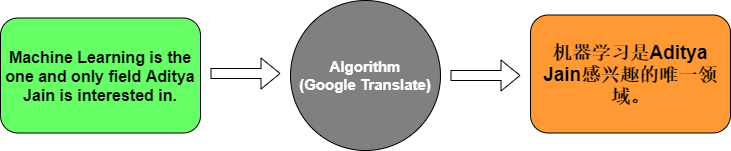

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0000e+00 - loss: 2.4868

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.0000e+00 - loss: 2.4868 - val_accuracy: 0.0000e+00 - val_loss: 2.4881


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5714 - loss: 2.4768

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5714 - loss: 2.4768 - val_accuracy: 0.0000e+00 - val_loss: 2.4907


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.8571 - loss: 0.5180 - val_accuracy: 0.0000e+00 - val_loss: 6.5799


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.5714 - loss: 1.8608

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 708ms/step - accuracy: 0.5714 - loss: 1.8608


Test Accuracy: 0.5714285969734192


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers**

1. **Embedding:** It turns each integer word ID into a dense vector of learned numbers. These vectors help the network represent relationships between words; the ID itself does not describe the word's meaning.
3. **Encoder LSTM:** It reads the English word vectors in order and summarizes the sentence in a context vector. Its memory helps it keep information about earlier words.
5. **Decoder LSTM:** It uses the encoded information to produce a sequence of hidden representations for the French sentence. In this model, RepeatVector supplies the context at every target time step, and the final Dense layer converts each decoder output into word scores.
8. **Softmax:** It converts the final scores into a probability distribution over the French vocabulary at each time step. The probabilities sum to one, and we can select the most likely word using argmax.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 — English-to-French translation solution

The following implementation trains the same Embedding → Encoder LSTM → RepeatVector → Decoder LSTM → Softmax architecture on the supplied bilingual dataset.

**Run:** Open this notebook in Google Colab and run the cells in order. A GPU is helpful. The dataset downloads automatically; if downloading is blocked, upload `eng_-french.csv` to the notebook's working directory. The optional installation cell below supplies the required packages.

**Execution status:** All code cells were executed successfully locally with Python 3.12 and TensorFlow. Actual training logs, plots, evaluation metrics, and example predictions are saved below.

Dataset: [Language Translation (English-French), Devicharith](https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench).

**Local training run:** The maximum was 30 epochs; training was stopped cleanly at the end of epoch 17 to limit CPU runtime. All evaluation cells completed using the resulting model. The scores below measure this educational baseline, not production translation quality.

In [8]:
# Run this cell only if the imports in the next cell fail.
# %pip install tensorflow pandas numpy scikit-learn matplotlib nltk

In [9]:
from pathlib import Path
import io
import zipfile
import urllib.request
import re
import unicodedata
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

tf.keras.utils.set_random_seed(42)
csv_path = Path('eng_-french.csv')
if csv_path.exists():
    data = pd.read_csv(csv_path)
else:
    url = 'https://www.kaggle.com/api/v1/datasets/download/devicharith/language-translation-englishfrench'
    with urllib.request.urlopen(url, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    member = next(name for name in archive.namelist() if name.endswith('.csv'))
    with archive.open(member) as csv_file:
        data = pd.read_csv(csv_file)

data = data[['English words/sentences', 'French words/sentences']].copy()
data.columns = ['english', 'french']
print('Original sentence pairs:', len(data))
display(data.head())

Original sentence pairs: 175621


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
# Normalize text while preserving French accents and apostrophes.
def clean_text(text):
    text = unicodedata.normalize('NFKC', str(text)).lower()
    text = text.replace('’', "'")
    text = re.sub(r"[^\w\s']", ' ', text, flags=re.UNICODE)
    return ' '.join(text.split())

pairs = data.dropna().copy()
for column in ['english', 'french']:
    pairs[column] = pairs[column].map(clean_text)
pairs = pairs[(pairs.english.str.len() > 0) & (pairs.french.str.len() > 0)]
pairs = pairs.drop_duplicates(['english', 'french'])
# Short sentences keep this introductory experiment manageable.
MAX_LENGTH = 12
pairs = pairs[(pairs.english.str.split().str.len() <= MAX_LENGTH) &
              (pairs.french.str.split().str.len() <= MAX_LENGTH)]
pairs = pairs.sample(n=min(20000, len(pairs)), random_state=42).reset_index(drop=True)

# Split by English sentence so alternate translations cannot leak across sets.
sources = pairs.english.unique()
train_sources, held_sources = train_test_split(sources, test_size=0.2, random_state=42)
val_sources, test_sources = train_test_split(held_sources, test_size=0.5, random_state=42)
train_df = pairs[pairs.english.isin(train_sources)].reset_index(drop=True)
val_df = pairs[pairs.english.isin(val_sources)].reset_index(drop=True)
test_df = pairs[pairs.english.isin(test_sources)].reset_index(drop=True)
print('Train / validation / test pairs:', len(train_df), len(val_df), len(test_df))

# Fit vocabularies on training text only. Zero is reserved for padding.
VOCAB_SIZE = 5000
task_eng_tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<unk>', filters='')
task_fr_tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<unk>', filters='')
task_eng_tokenizer.fit_on_texts(train_df.english)
task_fr_tokenizer.fit_on_texts(train_df.french)
eng_vocab_size = min(VOCAB_SIZE, len(task_eng_tokenizer.word_index) + 1)
fr_vocab_size = min(VOCAB_SIZE, len(task_fr_tokenizer.word_index) + 1)

def encode(texts, tokenizer):
    return pad_sequences(tokenizer.texts_to_sequences(list(texts)),
                         maxlen=MAX_LENGTH, padding='post', truncating='post')

x_train = encode(train_df.english, task_eng_tokenizer)
x_val = encode(val_df.english, task_eng_tokenizer)
x_test = encode(test_df.english, task_eng_tokenizer)
y_train = encode(train_df.french, task_fr_tokenizer)
y_val = encode(val_df.french, task_fr_tokenizer)
y_test = encode(test_df.french, task_fr_tokenizer)
print('Training shapes:', x_train.shape, y_train.shape)

Train / validation / test pairs: 15998 2004 1998


Training shapes: (15998, 12) (15998, 12)


In [11]:
# Match the lab's fixed-context encoder-decoder architecture.
task_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_LENGTH,), dtype='int32'),
    tf.keras.layers.Embedding(eng_vocab_size, 64, mask_zero=True),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.RepeatVector(MAX_LENGTH),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(fr_vocab_size, activation='softmax'))
])

# Ignore padded target positions in both loss and accuracy.
def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)
    return loss * mask * tf.math.divide_no_nan(tf.cast(tf.size(mask), loss.dtype), tf.reduce_sum(mask))

task_model.compile(
    optimizer='adam', loss=masked_loss,
    weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='token_accuracy')]
)
task_model.summary()
history = task_model.fit(
    x_train, y_train, sample_weight=(y_train != 0).astype('float32'),
    validation_data=(x_val, y_val, (y_val != 0).astype('float32')),
    epochs=30, batch_size=32,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=2
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 12, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 12, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 5000)       │       645,000 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,195,400 (4.56 MB)

 Trainable params: 1,195,400 (4.56 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


... (29 outputs left out)

Epoch 16/30


500/500 - 84s - 168ms/step - loss: 3.7404 - token_accuracy: 0.2778 - val_loss: 4.4723 - val_token_accuracy: 0.2439


Epoch 17/30


500/500 - 88s - 175ms/step - loss: 3.6412 - token_accuracy: 0.2848 - val_loss: 4.4647 - val_token_accuracy: 0.2462


Test loss: 4.405882358551025
Test token accuracy (excluding padding): 0.25104767084121704


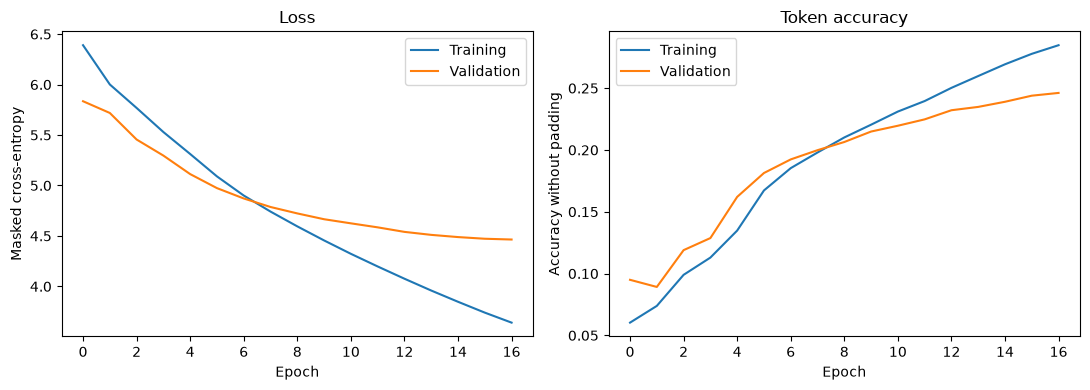

In [12]:
results = task_model.evaluate(
    x_test, y_test, sample_weight=(y_test != 0).astype('float32'),
    return_dict=True, verbose=0)
print('Test loss:', results['loss'])
print('Test token accuracy (excluding padding):', results['token_accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history['loss'], label='Training')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set(title='Loss', xlabel='Epoch', ylabel='Masked cross-entropy')
axes[1].plot(history.history['token_accuracy'], label='Training')
axes[1].plot(history.history['val_token_accuracy'], label='Validation')
axes[1].set(title='Token accuracy', xlabel='Epoch', ylabel='Accuracy without padding')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [13]:
def decode_ids(ids):
    return ' '.join(task_fr_tokenizer.index_word.get(int(i), '<unk>')
                    for i in ids if int(i) != 0)

def translate_english_to_french(sentence):
    cleaned = clean_text(sentence)
    if not cleaned:
        raise ValueError('Please enter a non-empty sentence.')
    encoded = encode([cleaned], task_eng_tokenizer)
    probabilities = task_model.predict(encoded, verbose=0)
    return decode_ids(np.argmax(probabilities[0], axis=-1))

# Held-out examples: compare predictions with actual references.
test_ids = np.argmax(task_model.predict(x_test, batch_size=32, verbose=0), axis=-1)
predictions = [decode_ids(row) for row in test_ids]
comparison = pd.DataFrame({'English': test_df.english,
                           'Reference French': test_df.french,
                           'Predicted French': predictions})
display(comparison.head(10))

# Include all available held-out references for each English sentence.
reference_map = test_df.groupby('english').french.apply(list).to_dict()
unique_test = comparison.drop_duplicates('English')
references = [[text.split() for text in reference_map[source]]
              for source in unique_test.English]
hypotheses = [text.split() for text in unique_test['Predicted French']]
bleu = corpus_bleu(references, hypotheses,
                   smoothing_function=SmoothingFunction().method1)
exact_match = np.mean([prediction in reference_map[source]
                      for source, prediction in zip(unique_test.English,
                                                    unique_test['Predicted French'])])
print(f'Test corpus BLEU: {bleu:.4f} (0–1 scale)')
print(f'Exact sentence match: {exact_match:.2%}')

for sentence in ['Hello.', 'How are you?', 'This product is very good.',
                 'The delivery was fast.', 'Thank you for your order.']:
    print(f'English: {sentence}\nPredicted French: {translate_english_to_french(sentence)}\n')

,English,Reference French,Predicted French
0,october is over,octobre est terminé,les <unk> sont agréable les <unk> <unk> <unk> ...
1,i'm tickled pink to be here,je suis très heureux d'être ici,je suis de de de ça ça ça moi moi moi moi
2,no one has anything,personne ne dispose de quoi que ce soit,personne ne pas pas qui qui faire faire faire ...
3,i'm at your mercy,je suis à votre merci,je suis <unk> <unk> <unk> <unk> <unk> <unk> <u...
4,i want you to remember this moment,je veux que vous vous rappeliez cet instant,je veux que vous vous vous le faire ce mainten...
5,i have eaten a lot this morning,j'ai beaucoup mangé ce matin,j'ai besoin faut de ce ce ce à à ce à à
6,it really annoys me when you do that,cela m'agace vraiment quand tu fais ça,c'est vous vous vous vous faire faire faire fa...
7,how can you not know,comment parviens tu à l'ignorer,comment ne tu tu pas pas pas pas pas pas pas pas
8,i bought the book,j'ai acheté le livre,j'ai <unk> à <unk> <unk> <unk> <unk> <unk> <un...
9,is there a gas station around here,y a t il une station service dans les environs,y a t il un un <unk> <unk> <unk> <unk> <unk> <...


Test corpus BLEU: 0.0228 (0–1 scale)
Exact sentence match: 0.00%
English: Hello.
Predicted French: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>



English: How are you?
Predicted French: comment vous vous vous vous vous <unk> <unk> <unk> <unk> vous vous

English: This product is very good.
Predicted French: ce est est trop <unk> temps <unk> <unk> <unk> <unk> <unk> <unk>



English: The delivery was fast.
Predicted French: la maison était été été été ouverte ouverte été été été été

English: Thank you for your order.
Predicted French: merci moi vous un de café café de <unk> <unk> <unk> <unk>



### Discussion

The Embedding learns word representations; the encoder summarizes the English sentence; RepeatVector repeats that summary; and the decoder and softmax predict French words at each position. Padding is excluded from the reported token accuracy because predicting padding correctly is not useful translation.

BLEU measures overlap with reference translations, while exact match is stricter. Actual values appear only after training. A low validation score or a widening training/validation loss gap suggests limited generalization or overfitting. These outcomes should be interpreted from the generated plots and test scores rather than assumed in advance.

This is an educational baseline. It uses a limited vocabulary, truncates inputs beyond 12 words, and does not explicitly condition each predicted word on the previously generated word. The source corpus contains general sentences rather than specialized product listings and reviews. For the e-commerce use case, collect representative bilingual product and review data, preserve prices and product identifiers, and assess translations with French-speaking reviewers. More data, an attention-based encoder-decoder, or a pretrained translation model would be useful next experiments.